# "Tutorial" on Avrami
Simple case on Avrami equation, using a lot of train points, with no noise, and known Ea and A.

In [1]:
import functools
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn import preprocessing, pipeline, linear_model
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as thdat

#from Network_PINNS import Net, NetDiscovery
#from diff_equations import *

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(0)


In [2]:
def grad(outputs, inputs):
    """Computes the partial derivative of 
    an output with respect to an input.
    Args:
        outputs: (N, 1) tensor
        inputs: (N, D) tensor
    """
    return torch.autograd.grad(
        outputs, inputs, grad_outputs=torch.ones_like(outputs), create_graph=True
    )

#Avrami equation: R(t) = Rmax { 1 - exp [ - (A exp ( - Ea / RT ) * t )^n ] }
# R(t): particle radius over time, k = A*exp(-Ea/RT): rate constant (Arrhenius), n: Avrami exponent
def avrami_law(t,Ea,R,T,A,n,r_max):
    K = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-K * t**n))

    return d

In [22]:
def np_to_tensor(x):
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

class Net(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
        nn.Linear(input_dim, self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        nn.Linear(self.n_units,self.n_units),
        nn.ReLU(),
        )
        self.out = nn.Linear(self.n_units, output_dim)
    
    def forward(self, x):
        h = self.layers(x)
        out = self.out(h)
        
        return out

    def fit(self, X, y):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)
            data_loss = self.loss(yt, outputs)
            if self.loss2:
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
            else:
                loss = data_loss
            data_losses.append(data_loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                else:
                    physic_loss_avg = 0

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

## This class Net architecture is our base architecture which we can use for all the purposes for nn. We can also customise it
## to add loss2 if we want.

class NetDiscovery(Net):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss=nn.MSELoss(), lr=0.001, loss2=None, loss2_weight=0.1,) -> None:
        super().__init__( input_dim, output_dim, n_units, epochs, loss, lr, loss2, loss2_weight)
        self.r = nn.Parameter(data=torch.tensor([0.]))

## This architecture is specifically for some discovery of a parameter which is initialized to 0 at the beginning. This one is for specific
# discovery of a parameter, in our case we are not utilising this class.

In [4]:
def create_avrami_data(n_points=50, A=1e-4, Ea=60000, T=500, r_max=30e-7, n=2.5):
    # -----------------------------
# Avrami Equation Parameter Notes
# -----------------------------
# The Avrami growth model: 
#   r(t) = r_max * (1 - exp(-K * t^n))
# Where:
#   - r(t): radius at time t
#   - r_max: maximum possible radius (controls final size)
#   - n: Avrami exponent (controls shape of growth curve)
#       > Higher n = sharper sigmoid shape
#   - K: rate constant, K = A * exp(-Ea / (R * T))
#       > A: frequency factor (higher A = faster growth)
#       > Ea: activation energy (higher Ea = slower growth)
#       > T: temperature in Kelvin (higher T = faster growth)
#       > R: gas constant (8.314 J/mol·K)
#
# Summary of effects:
#   ↑ A or T → faster growth
#   ↑ Ea     → slower growth
#   ↑ n      → more "sigmoid" curve
#   ↑ r_max  → higher final radius

    R = 8.314
    t = np.linspace(0, 36000, n_points)
    k = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-(k * t**n)))
    return t, d

# Get data
t, d = create_avrami_data()
#noise_std = 0.001  # You can adjust this
d_nm = d * 1e9  # Convert to nanometers
# Scale up data just for fitting/visualization (don't affect model internals)
#d_nm_noisy = d_nm + np.random.normal(0, noise_std, size=d_nm.shape)

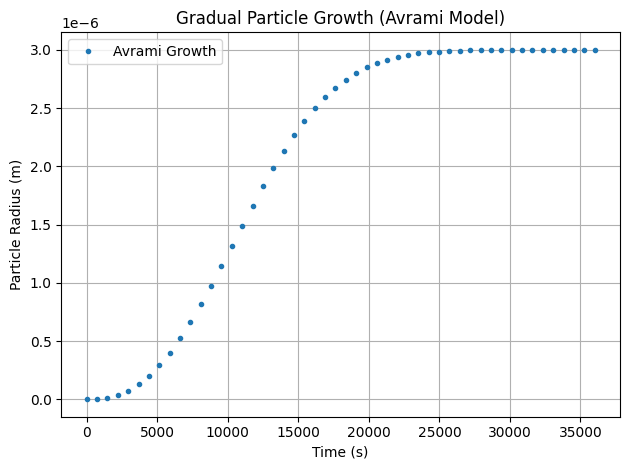

In [5]:
t, d = create_avrami_data()

plt.plot(t, d, '.', label='Avrami Growth')
plt.xlabel("Time (s)")
plt.ylabel("Particle Radius (m)")
plt.title("Gradual Particle Growth (Avrami Model)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

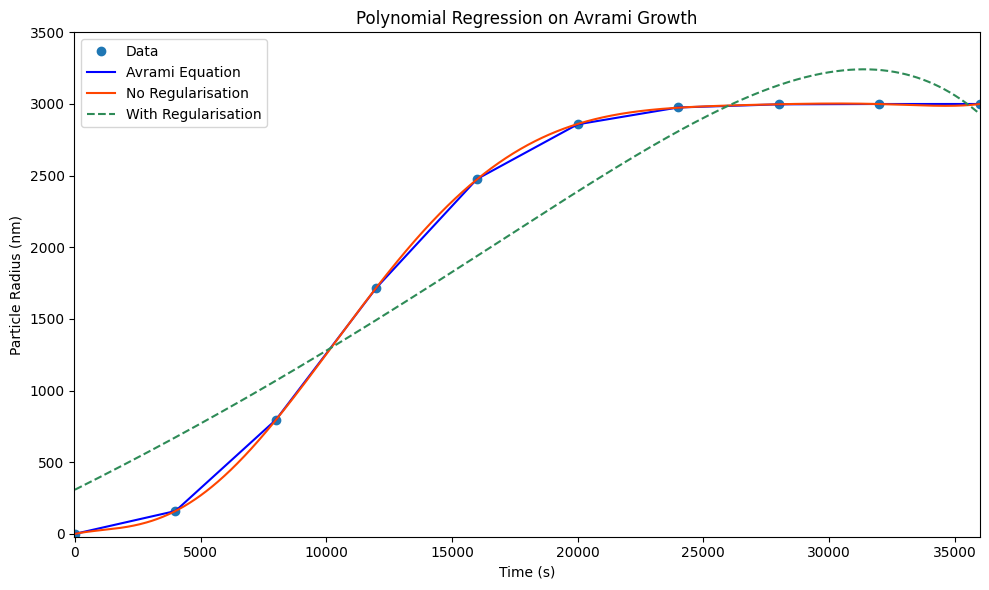

In [6]:
# -------- Define Models --------
model = pipeline.Pipeline([
    ('poly', preprocessing.PolynomialFeatures(degree=8)),
    ('scaler', preprocessing.StandardScaler()),
    ('reg', linear_model.LinearRegression())
])

model_l2 = pipeline.Pipeline([
    ('poly', preprocessing.PolynomialFeatures(degree=8)),
    ('scaler', preprocessing.StandardScaler()),
    ('reg', linear_model.Ridge(alpha=1))
])

t, d = create_avrami_data(10)

# -------- Fit Models --------
d_nm = d * 1e9  # convert to nm
model.fit(t.reshape(-1, 1), d_nm.reshape(-1, 1))
model_l2.fit(t.reshape(-1, 1), d_nm.reshape(-1, 1))

# -------- Predict --------
t_pred = np.linspace(t.min(), t.max(), 1000).reshape(-1, 1)
d_pred = model.predict(t_pred)
d_pred_l2 = model_l2.predict(t_pred)


# -------- Plot --------
plt.figure(figsize=(10, 6))
plt.plot(t, d_nm, 'o', label='Data')
plt.plot(t, d_nm, label='Avrami Equation', color='blue')
plt.plot(t_pred, d_pred, label='No Regularisation', color='orangered')
plt.plot(t_pred, d_pred_l2, label='With Regularisation', color='seagreen', linestyle='--')

plt.xlabel("Time (s)")
plt.ylabel("Particle Radius (nm)")
plt.title("Polynomial Regression on Avrami Growth")
plt.xlim(-20, 36000)  # full time range
plt.ylim(-20, 3500)
plt.legend()
plt.tight_layout()
plt.show()


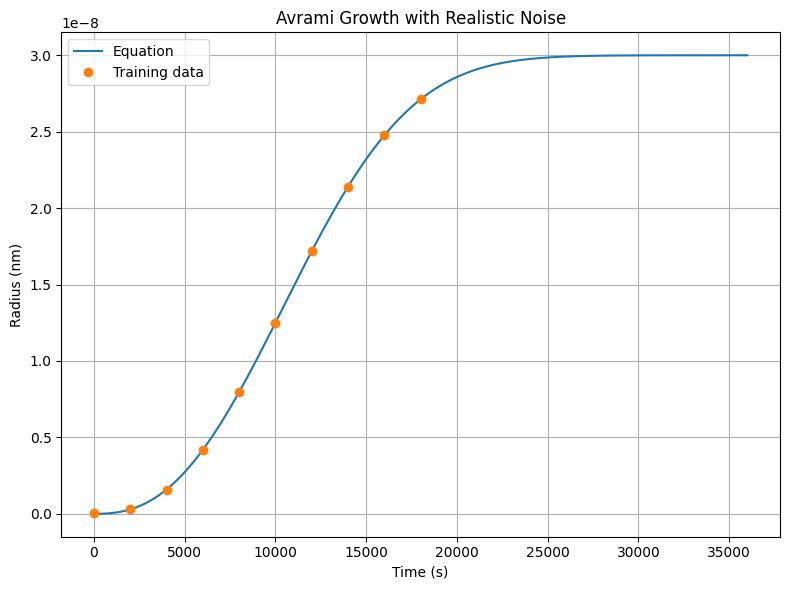

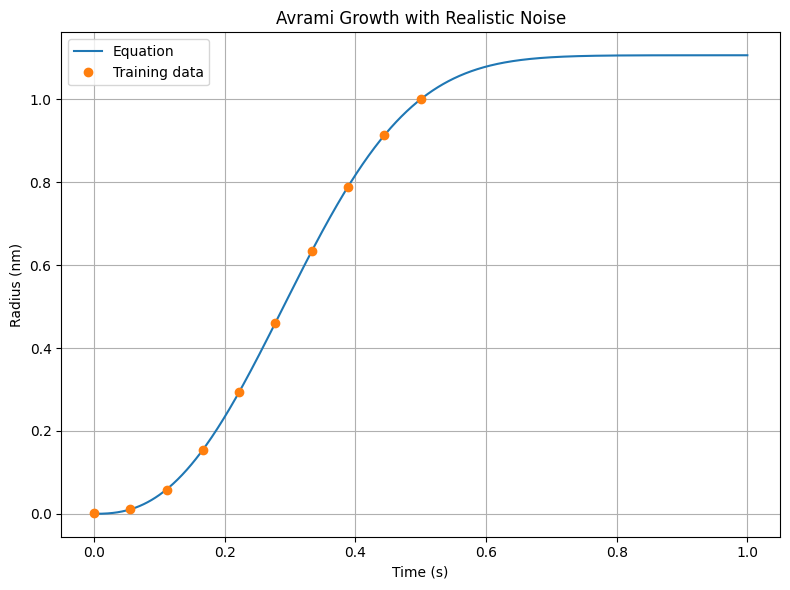

In [7]:
# Parameters
# -----------------------------
# Avrami Equation Parameter Notes
# -----------------------------
# The Avrami growth model: 
#   r(t) = r_max * (1 - exp(-K * t^n))
# Where:
#   - r(t): radius at time t
#   - r_max: maximum possible radius (controls final size)
#   - n: Avrami exponent (controls shape of growth curve)
#       > Higher n = sharper sigmoid shape
#   - K: rate constant, K = A * exp(-Ea / (R * T))
#       > A: frequency factor (higher A = faster growth)
#       > Ea: activation energy (higher Ea = slower growth)
#       > T: temperature in Kelvin (higher T = faster growth)
#       > R: gas constant (8.314 J/mol·K)
#
# Summary of effects:
#   ↑ A or T → faster growth
#   ↑ Ea     → slower growth
#   ↑ n      → more "sigmoid" curve
#   ↑ r_max  → higher final radius


# ----------------------------------------------
# Avrami Curve Shape: Sigmoid vs. Exponential-like
# ----------------------------------------------
# The Avrami growth curve:
#   r(t) = r_max * (1 - exp(-K * t^n))
# Typically produces an S-shaped (sigmoid) curve:
#   - Slow start → rapid growth → saturation
#
# K = A * exp(-Ea / (R * T)) controls the growth rate:
#   ↑ A (pre-exponential factor)   → faster transformation
#   ↓ Ea (activation energy)       → faster transformation
#   ↑ T (temperature in Kelvin)    → faster transformation
#
# Curve shape transitions based on K:
# ---------------------------------------------------------
# | K value   | Shape            | Cause                  |
# |---------- |------------------|------------------------|
# | Small     | Exponential-like | ↑ Ea, ↓ T, ↓ A         |
# | Moderate  | Sigmoid (normal) | Balanced parameters    |
# | Large     | Steep sigmoid    | ↓ Ea, ↑ T, ↑ A         |
# ---------------------------------------------------------
#
# When K is very small, only the initial part of the curve appears,
# making it look linear or exponential-like instead of S-shaped.

np.random.seed(10)
A = 1e-4              # Increased to speed up transformation
Ea = 60000           # Lowered to increase reaction rate
T = 500             # Higher temp for faster growth
r_max = 30e-9       # Max radius in meters (30 nm)
n = 2.5
R = 8.314
# Time array
times = np.linspace(0, 36000, 1000)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
d1 = eq(times) # * 1e9

# Training data with noise
N_POINTS = 10
t = np.linspace(0, 36000//2, N_POINTS)
noise_std = 0.001 * r_max
d = (eq(t) + noise_std * np.random.randn(N_POINTS)) # * 1e9


MAX_X = times.max()
MAX_Y = d.max()



# Plot
plt.figure(figsize=(8, 6))
plt.plot(times, d1, label="Equation")
plt.plot(t, d, 'o', label="Training data")
plt.legend()
plt.ylabel('Radius (nm)')
plt.xlabel('Time (s)')
plt.title('Avrami Growth with Realistic Noise')
plt.grid(True)
plt.tight_layout()
plt.show()

times = times/MAX_X
t = t/MAX_X
d1 = d1/MAX_Y
d = d/MAX_Y

# Plot
plt.figure(figsize=(8, 6))
plt.plot(times, d1, label="Equation")
plt.plot(t, d, 'o', label="Training data")
plt.legend()
plt.ylabel('Radius (nm)')
plt.xlabel('Time (s)')
plt.title('Avrami Growth with Realistic Noise')
plt.grid(True)
plt.tight_layout()
plt.show()



Epoch 0/100000, loss: 0.270594 - data_loss: 0.270594 - physic_loss: 0.000000
Epoch 10000/100000, loss: 0.021234 - data_loss: 0.021234 - physic_loss: 0.000000
Epoch 20000/100000, loss: 0.010618 - data_loss: 0.010618 - physic_loss: 0.000000
Epoch 30000/100000, loss: 0.007079 - data_loss: 0.007079 - physic_loss: 0.000000
Epoch 40000/100000, loss: 0.005309 - data_loss: 0.005309 - physic_loss: 0.000000
Epoch 50000/100000, loss: 0.004247 - data_loss: 0.004247 - physic_loss: 0.000000
Epoch 60000/100000, loss: 0.003539 - data_loss: 0.003539 - physic_loss: 0.000000
Epoch 70000/100000, loss: 0.003034 - data_loss: 0.003034 - physic_loss: 0.000000
Epoch 80000/100000, loss: 0.002655 - data_loss: 0.002655 - physic_loss: 0.000000
Epoch 90000/100000, loss: 0.002360 - data_loss: 0.002360 - physic_loss: 0.000000


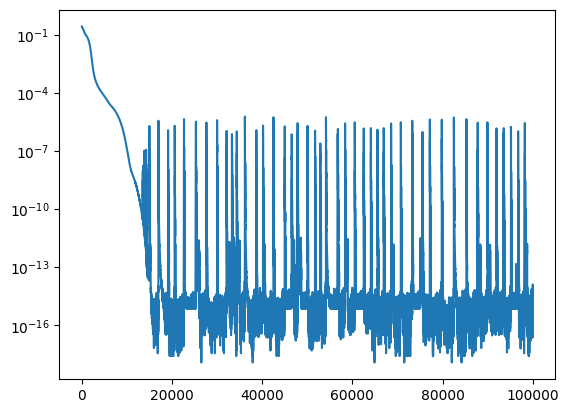

In [25]:
set_seed(0)
vanilla = Net(1,1, loss2=None, epochs=100000, lr=1e-5).to(DEVICE)

losses = vanilla.fit(t, d)

plt.plot(losses)
plt.yscale('log')

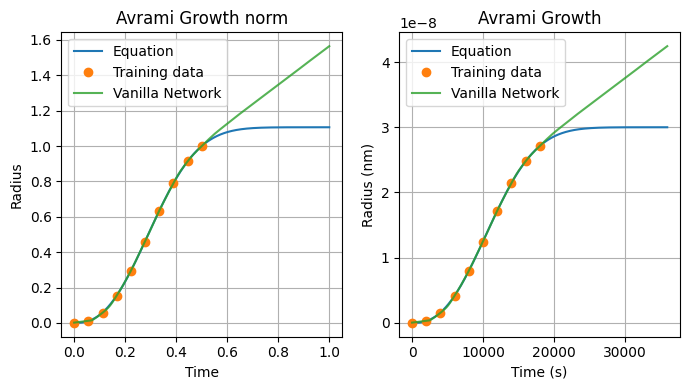

In [29]:
# Unscale model predictions (if models were trained on normalized radius)
# r_max = 30e-9  # max radius in meters

# predsreg = netreg.predict(times) # * r_max  # unscale to meters
vanilla_preds = vanilla.predict(times) # * MAX_Y        # unscale to meters

# Plot everything in nanometers (1e9)
plt.figure(figsize=(7, 4))
plt.subplot(121)
plt.plot(times, d1, label='Equation')            # true Avrami curve
plt.plot(t, d , 'o', label='Training data')       # noisy data
plt.plot(times, vanilla_preds, label='Vanilla Network', alpha=0.8)
# plt.plot(times, predsreg * 1e9, label='L2 Network', alpha=0.8)

plt.legend()
plt.ylabel('Radius')
plt.xlabel('Time')
plt.title('Avrami Growth norm')
plt.grid(True)


plt.subplot(122)
plt.plot(times* MAX_X, d1* MAX_Y , label='Equation')            # true Avrami curve
plt.plot(t*MAX_X, d * MAX_Y , 'o', label='Training data')       # noisy data
plt.plot(times*MAX_X, vanilla_preds*MAX_Y, label='Vanilla Network', alpha=0.8)
plt.legend()
plt.ylabel('Radius (nm)')
plt.xlabel('Time (s)')
plt.title('Avrami Growth')
plt.grid(True)

plt.tight_layout()
plt.show()


# PINN

Epoch 0/300000, loss: 1.694906 - data_loss: 0.270594 - physic_loss: 1.424312
Epoch 30000/300000, loss: 0.022073 - data_loss: 0.000705 - physic_loss: 0.021368
Epoch 60000/300000, loss: 0.024228 - data_loss: 0.000413 - physic_loss: 0.023816
Epoch 90000/300000, loss: 0.028162 - data_loss: 0.000353 - physic_loss: 0.027810
Epoch 120000/300000, loss: 0.031119 - data_loss: 0.000336 - physic_loss: 0.030784
Epoch 150000/300000, loss: 0.034903 - data_loss: 0.000352 - physic_loss: 0.034551
Epoch 180000/300000, loss: 0.036246 - data_loss: 0.000348 - physic_loss: 0.035898
Epoch 210000/300000, loss: 0.037188 - data_loss: 0.000344 - physic_loss: 0.036844
Epoch 240000/300000, loss: 0.038466 - data_loss: 0.000349 - physic_loss: 0.038117
Epoch 270000/300000, loss: 0.039751 - data_loss: 0.000357 - physic_loss: 0.039394


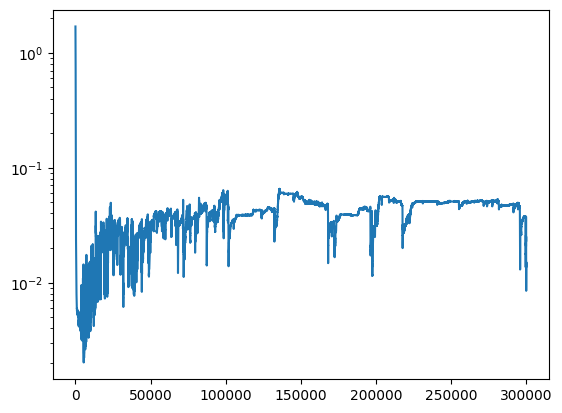

In [ ]:
if not isinstance(Ea, torch.Tensor):
    # to allow physics loss to treat every other constants as tensors
    Ea = torch.tensor(Ea, dtype=torch.float32, device=DEVICE)

def physics_loss(model: torch.nn.Module):
    # Create time input for PINN
    # ts = torch.linspace(0, 5000, steps=5000).view(-1, 1).to(DEVICE).requires_grad_(True)  # 5000
    # ts_dense = torch.linspace(5000, 10000, steps=10000).view(-1, 1).to(DEVICE).requires_grad_(True)  # 10000
    # ts = torch.cat([ts, ts_dense], dim=0)

    # 36000, 1000
    ts = torch.linspace(0, 36000, steps=1000).view(-1, 1).to(DEVICE).requires_grad_(True)
    # ts_dense = torch.linspace(36000//2, 36000, steps=1000).view(-1, 1).to(DEVICE).requires_grad_(True)
    # ts = torch.cat([ts, ts_dense], dim=0)

    # Predict radius
    d = model(ts / MAX_X) * MAX_Y
    
    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Convert constants to tensors
    # T_ = torch.tensor(T, dtype=torch.float32, device=DEVICE)
    # R_ = torch.tensor(R, dtype=torch.float32, device=DEVICE)
    # Ea_ = torch.tensor(Ea, dtype=torch.float32, device=DEVICE)
    # A_ = torch.tensor(A, dtype=torch.float32, device=DEVICE)
    # r_max_ = torch.tensor(30e-9, dtype=torch.float32, device=DEVICE)
    # n_ = torch.tensor(n, dtype=torch.float32, device=DEVICE)

    # # Compute K
    # K = A_ * torch.exp(-Ea_ / (R_ * T_))

    # # Theoretical Avrami derivative
    # derived_eq = r_max_ * K * n_ * ts.pow(n_ - 1) * torch.exp(-K * ts.pow(n_))

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = r_max * K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    pde_residual = pde_residual * 1e12
    physical_loss = torch.mean(pde_residual**2)
    return physical_loss


set_seed(0)
net = Net(1, 1, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4, patience=0).to(DEVICE)
losses = net.fit(t, d)

plt.plot(losses)
plt.yscale('log')

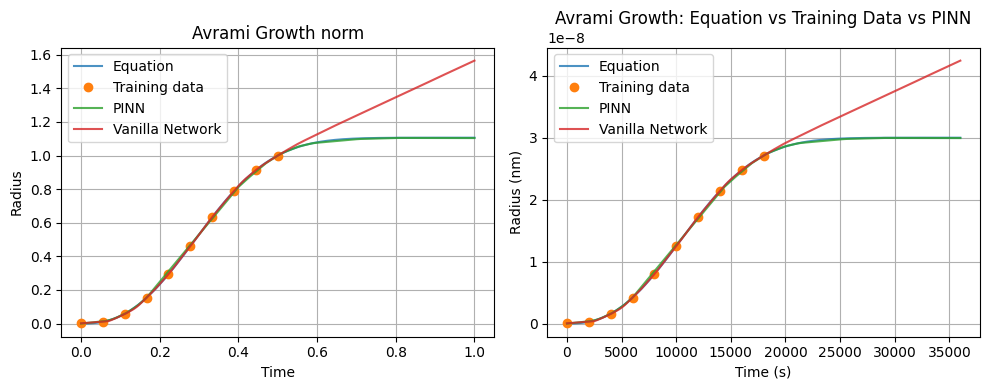

In [32]:
# Prepare input for model
ts_tensor = torch.tensor(times).float().view(-1, 1).to(DEVICE)

# Predict and unscale
preds = net(ts_tensor).detach().cpu().numpy() # * r_max  # unscale prediction

# Plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.plot(times, d1, label='Equation', alpha=0.8)          # True curve
plt.plot(t, d , 'o', label='Training data')                # Noisy data
plt.plot(times, preds , label='PINN', alpha=0.8)           # PINN prediction
plt.plot(times, vanilla_preds, label="Vanilla Network", alpha=0.8)
plt.legend()
plt.ylabel('Radius')
plt.xlabel('Time')
plt.title('Avrami Growth norm')
plt.grid(True)

# Plot
plt.subplot(122)
plt.plot(times*MAX_X, d1*MAX_Y, label='Equation', alpha=0.8)          # True curve
plt.plot(t*MAX_X, d*MAX_Y, 'o', label='Training data')                # Noisy data
plt.plot(times*MAX_X, preds*MAX_Y, label='PINN', alpha=0.8)           # PINN prediction
plt.plot(times*MAX_X, vanilla_preds*MAX_Y, label="Vanilla Network", alpha=0.8)
plt.legend()
plt.ylabel('Radius (nm)')
plt.xlabel('Time (s)')
plt.title('Avrami Growth: Equation vs Training Data vs PINN')
plt.grid(True)

plt.tight_layout()
plt.show()
